In [2]:
import rasterio
from rasterio.plot import plotting_extent
import shapely
import numpy as np
import os
import matplotlib.pyplot as plt
import rasterio.plot

# Processing Digital Surface Model (DSM) TIFF file

In [3]:
img_path = r'data/raw/ALPSMLC30_N043E100_DSM.tif'
ds = rasterio.open(img_path)
ds

data = ds.read(1)

In [4]:
data

array([[1242, 1241, 1241, ..., 1153, 1154, 1154],
       [1241, 1241, 1241, ..., 1154, 1154, 1153],
       [1239, 1239, 1240, ..., 1154, 1150, 1151],
       ...,
       [1394, 1393, 1391, ..., 1508, 1508, 1509],
       [1393, 1392, 1391, ..., 1508, 1509, 1509],
       [1392, 1392, 1390, ..., 1510, 1509, 1510]],
      shape=(3600, 3600), dtype=int16)

In [4]:
ds.meta

{'driver': 'GTiff',
 'dtype': 'int16',
 'nodata': -9999.0,
 'width': 3600,
 'height': 3600,
 'count': 1,
 'crs': CRS.from_wkt('GEOGCS["WGS 84",DATUM["World Geodetic System 1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]]'),
 'transform': Affine(0.0002777777777777778, 0.0, 100.0,
        0.0, -0.0002777777777777778, 44.0)}

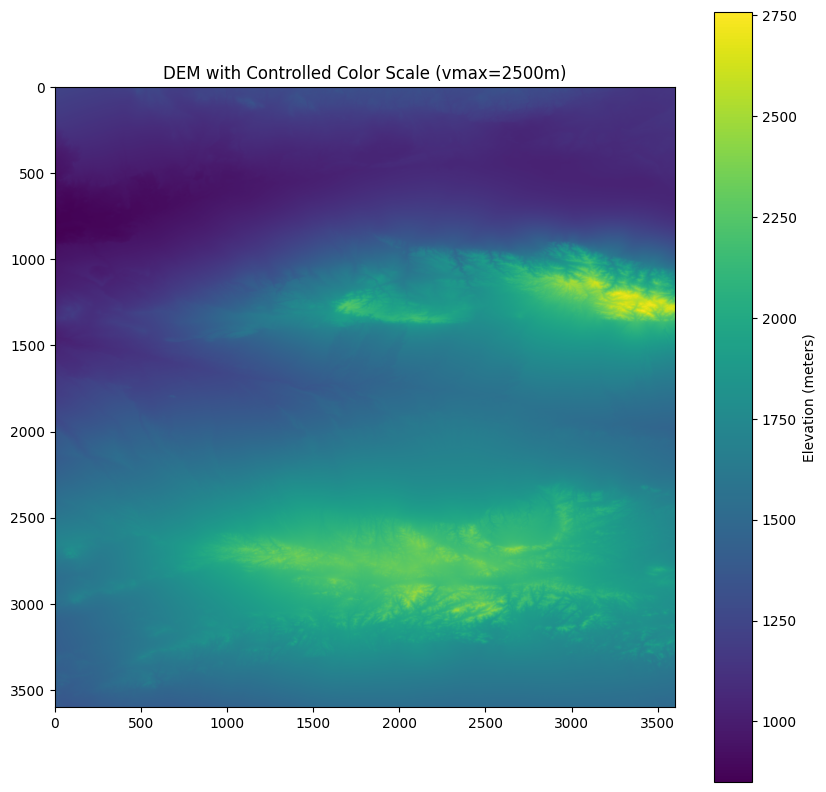

In [5]:
with rasterio.open(img_path) as src:
    elevation_masked = np.ma.masked_equal(src.read(1), src.nodata)

    # --- Plot with manual color limits ---
    fig, ax = plt.subplots(figsize=(10, 10))
    
    # Manually set the max color value to something less than the true max.
    # This will make the peaks "saturate" to the max color, but will
    # reveal much more detail in the rest of the terrain.
    im = ax.imshow(elevation_masked, cmap='viridis') 
    
    ax.set_title("DEM with Controlled Color Scale (vmax=2500m)")
    fig.colorbar(im, label="Elevation (meters)")
    plt.show()

# Now, clean tile with MSK mask
* "A typical workflow involves reading the DSM and mask files, applying a mask to exclude invalid or void-filled area
* Transparency, acknowledging margin of error, a

In [6]:
msk_path = r'data/raw/ALPSMLC30_N043E100_MSK.tif'
ds = rasterio.open(msk_path)
ds

ds.read(1)

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(3600, 3600), dtype=uint8)

In [7]:
dsm_path = r'data/raw/ALPSMLC30_N043E100_DSM.tif'
msk_path = r'data/raw/ALPSMLC30_N043E100_MSK.tif'
output_path = r'data/ALPSMLC30_N043E100_DSM_cleaned.tif'

with rasterio.open(dsm_path) as dsm_src, rasterio.open(msk_path) as msk_src:

    dsm_array = dsm_src.read(1)
    msk_array = msk_src.read(1)

    # Identifying DSM 'nodata' flag value
    out_meta = dsm_src.profile.copy()
    nodata_value = out_meta['nodata']
    print(out_meta)
    print('No Data Value =', nodata_value)
    
    # Boolean mask MSK array for invalid pixels
    invalid_pixels_mask = (msk_array != 0)

    cleaned_dsm_array = dsm_array.copy()
    
    # Mask invalid pixels with 'nodata' flag
    cleaned_dsm_array[invalid_pixels_mask] = nodata_value
    print(f"Identified and masked {np.sum(invalid_pixels_mask)} invalid pixels out of {dsm_array.size}.")

    with rasterio.open(output_path, "w", **out_meta) as dest:
        dest.write(cleaned_dsm_array, 1)
        

{'driver': 'GTiff', 'dtype': 'int16', 'nodata': -9999.0, 'width': 3600, 'height': 3600, 'count': 1, 'crs': CRS.from_wkt('GEOGCS["WGS 84",DATUM["World Geodetic System 1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]]'), 'transform': Affine(0.0002777777777777778, 0.0, 100.0,
       0.0, -0.0002777777777777778, 44.0), 'blockxsize': 3600, 'blockysize': 1, 'tiled': False, 'interleave': 'band'}
No Data Value = -9999.0
Identified and masked 16230 invalid pixels out of 12960000.


In [8]:
print(cleaned_dsm_array)

[[1242 1241 1241 ... 1153 1154 1154]
 [1241 1241 1241 ... 1154 1154 1153]
 [1239 1239 1240 ... 1154 1150 1151]
 ...
 [1394 1393 1391 ... 1508 1508 1509]
 [1393 1392 1391 ... 1508 1509 1509]
 [1392 1392 1390 ... 1510 1509 1510]]


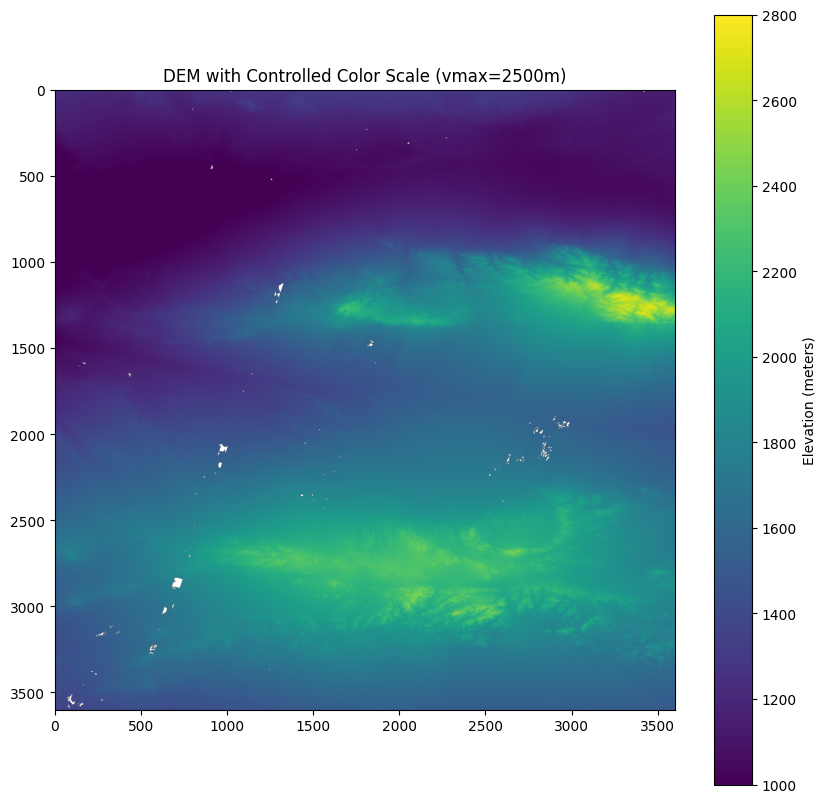

In [9]:
import matplotlib.pyplot as plt
import numpy as np
masked_tile_path = r'data/ALPSMLC30_N043E100_DSM_cleaned.tif'
with rasterio.open(masked_tile_path) as src:
    elevation_masked = np.ma.masked_equal(src.read(1), src.nodata)

    # --- Plot with manual color limits ---
    fig, ax = plt.subplots(figsize=(10, 10))
    
    # Manually set the max color value to something less than the true max.
    # This will make the peaks "saturate" to the max color, but will
    # reveal much more detail in the rest of the terrain.
    im = ax.imshow(elevation_masked, cmap='viridis', vmin=1000, vmax=2800) 
    
    ax.set_title("DEM with Controlled Color Scale (vmax=2500m)")
    fig.colorbar(im, label="Elevation (meters)")
    plt.show

# Automate the cleaning process

In [10]:
data_directory = r'data/raw'
output_directory = r'data/cleaned'

for filename in os.listdir(data_directory):
    if '_DSM.' in filename:
        msk_filename = filename.replace('_DSM.', '_MSK.')
        
        dsm_path = os.path.join(data_directory, filename)
        msk_path = os.path.join(data_directory, msk_filename)
        
        if os.path.exists(msk_path):
            output_filename = filename.replace('_DSM.', '_cleaned.')
            output_path = os.path.join(output_directory, output_filename)
            
        with rasterio.open(dsm_path) as dsm_src, rasterio.open(msk_path) as msk_src:

            dsm_array = dsm_src.read(1)
            msk_array = msk_src.read(1)
        
            # Identifying DSM 'nodata' flag value
            out_meta = dsm_src.profile.copy()
            nodata_value = out_meta['nodata']
            
            # Boolean mask MSK array for invalid pixels
            invalid_pixels_mask = (msk_array != 0)
        
            cleaned_dsm_array = dsm_array.copy()
        
            # Mask invalid pixels with 'nodata' flag
            cleaned_dsm_array[invalid_pixels_mask] = nodata_value
            print(f"{output_filename} identified and masked {np.sum(invalid_pixels_mask)} invalid pixels. ({(np.sum(invalid_pixels_mask) / dsm_array.size) * 100:.2f}%)")

            with rasterio.open(output_path, "w", **out_meta) as dest:
                dest.write(cleaned_dsm_array, 1)

        

ALPSMLC30_N042E099_cleaned.tif identified and masked 76748 invalid pixels. (0.59%)
ALPSMLC30_N042E100_cleaned.tif identified and masked 72978 invalid pixels. (0.56%)
ALPSMLC30_N042E101_cleaned.tif identified and masked 66373 invalid pixels. (0.51%)
ALPSMLC30_N043E099_cleaned.tif identified and masked 39785 invalid pixels. (0.31%)
ALPSMLC30_N043E100_cleaned.tif identified and masked 16230 invalid pixels. (0.13%)
ALPSMLC30_N043E101_cleaned.tif identified and masked 9950 invalid pixels. (0.08%)


# Retrieve appended reserve TIFF from GDAL (gdal_merge.py)

In [11]:
img_path = r'data/reserve_merged.tif'
ds = rasterio.open(img_path)
ds

ds.read(1)

array([[1377, 1379, 1382, ..., 1060, 1060, 1061],
       [1380, 1381, 1382, ..., 1060, 1060, 1061],
       [1382, 1381, 1381, ..., 1060, 1060, 1061],
       ...,
       [1421, 1423, 1423, ..., 1001, 1003, 1002],
       [1419, 1418, 1419, ..., 1000, 1002, 1001],
       [1418, 1417, 1417, ..., 1001, 1001, 1001]],
      shape=(7200, 10800), dtype=int16)

In [12]:
ds.meta

{'driver': 'GTiff',
 'dtype': 'int16',
 'nodata': -9999.0,
 'width': 10800,
 'height': 7200,
 'count': 1,
 'crs': CRS.from_wkt('GEOGCS["WGS 84",DATUM["World Geodetic System 1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]]'),
 'transform': Affine(0.0002777777777777778, 0.0, 99.0,
        0.0, -0.0002777777777777778, 44.0)}

In [14]:
show(ds)

NameError: name 'show' is not defined

# Reprojection from Global Coordinate System to Projected Coordinate System
* (GCS WGS 84 Datum) to (PCS Universal Transverse Mercator UTS)
* Reprojection uses resampling (KNN/Bilinear Interpolation) to create new raster based on original pixel values 
* Zone 47N (EPSG:32647): Western Mongolia (96°E to 102°E)

In [24]:
img_path = r'data/reserve_UTM47N.tif'
ds = rasterio.open(img_path)
ds
data = ds.read(1)

<function matplotlib.pyplot.show(close=None, block=None)>

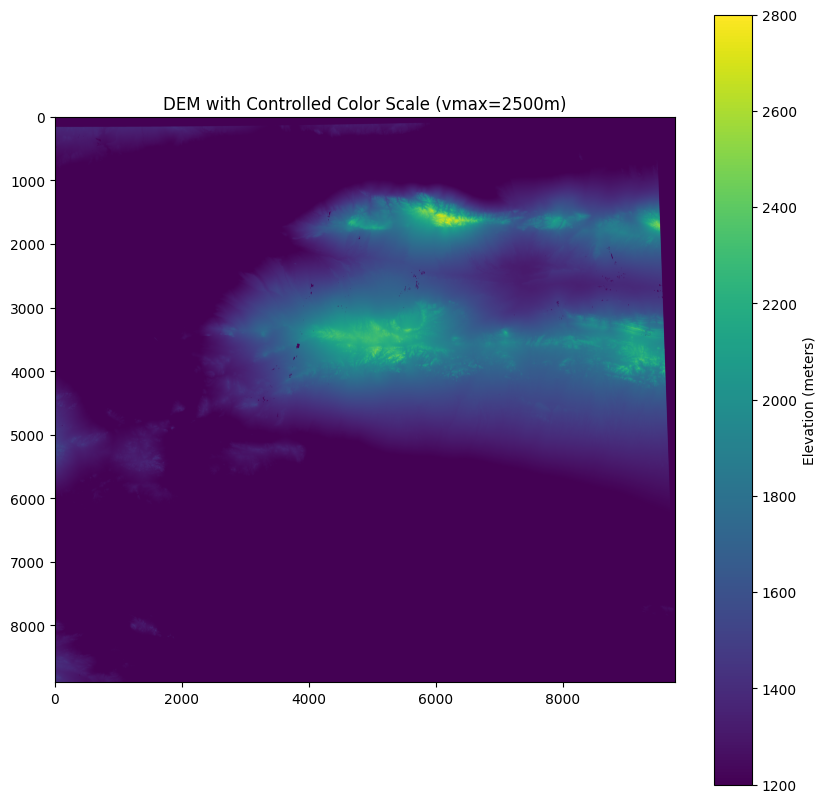

In [25]:
fig, ax = plt.subplots(figsize=(10, 10))


im = ax.imshow(data, cmap='viridis', vmin=1200, vmax=2800) 

ax.set_title("DEM with Controlled Color Scale (vmax=2500m)")
fig.colorbar(im, label="Elevation (meters)")
plt.show

In [26]:
with rasterio.open(dsm_input_path) as dsm_src:
    
    elevation = dsm_src.read()
    nodata = dsm_src.nodata
    # Create a masked array to safely calculate stats
    elevation_masked = np.ma.masked_equal(elevation, nodata)

    print(f"Before filtering max elevation (potential error):{elevation_masked.max()}meters")


NameError: name 'dsm_input_path' is not defined